# Reading ESRI TIN datasets with `pyramids-mesh`

An **ESRI TIN** (Triangulated Irregular Network) is not a single file but a **directory** of Arc/Info `.adf` binaries — `tnod.adf`, `tnxy.adf`, `tedg.adf`, `tnz.adf` and friends — that together store a triangulated surface: node coordinates, edges, and per-node elevation. It is ArcGIS's native vector-surface format.

`pyramids-mesh` registers an `esri_tin` **driver**. Because the dataset is a folder, we point the reader at the **directory**, not a file. This notebook reads a small `dem` TIN and walks read → explore → plot → GIS.

## 1. Pin the plotting backend

Figures are rendered through `cleopatra` (matplotlib). So the notebook runs identically under
CI and interactively, we pin the non-interactive **`Agg`** backend *before* importing `pyplot`,
and define a tiny `show()` helper that grabs the current figure, saves it to an in-memory PNG and
embeds it inline. With `Agg` a bare `plt.show()` embeds nothing, so every plot below ends with a
`show()` call instead.

In [1]:
import os
os.environ["MPLBACKEND"] = "Agg"
import matplotlib; matplotlib.use("Agg")
%matplotlib inline
import matplotlib.pyplot as plt
from IPython.display import Image, display
def show():
    from io import BytesIO
    buf = BytesIO(); plt.gcf().savefig(buf, format="png", dpi=110, bbox_inches="tight")
    plt.close("all"); buf.seek(0); display(Image(data=buf.read()))

## 2. Imports

The import below is all the setup this adds: `UgridDataset` is the object every driver hands back (a `Mesh2d` or `Network1d` wrapper). Importing from `pyramids` also puts its vendored GDAL/PROJ data in place for you, so nothing about it is order-sensitive in a notebook -- just import the names you use.

In [2]:
from pyramids.netcdf.ugrid import UgridDataset
import numpy as np
from pathlib import Path

## 3. Locate the data

The notebook lives in `docs/examples/`, so `examples/data/` is two levels up. We pass a `pathlib.Path` to the reader (never a string).

In [3]:
DATA = Path("../../examples/data")
src = DATA / "esri_tin" / "dem"
print("is directory:", src.is_dir())
sorted(p.name for p in src.iterdir())[:8]

is directory: True


['metadata.xml',
 'prj.adf',
 'tdenv9.adf',
 'tedg.adf',
 'teval.adf',
 'thul.adf',
 'tmsk.adf',
 'tmsx.adf']

## 4. Read the mesh

We name the driver explicitly: `driver="esri_tin"`. `read_file` dispatches to it and returns a `UgridDataset` wrapping a `Mesh2d`.

In [4]:
ds = UgridDataset.read_file(src, driver="esri_tin")
ds

C:\python-environments\worktrees\pyramids-mesh\example-notebooks\src\pyramids_mesh\_base.py:484: UserWarning: 528 clockwise face(s) were reversed to counter-clockwise; a writer will emit the corrected order
  parsed = validate_and_normalise(parsed)


UgridDataset(mesh='mesh2d', n_node=281, n_face=528, n_edge=0, variables=['node_z'])

## 5. Explore the mesh

Node/face counts, CRS, the attached data variables and the bounding box. This TIN has 281 nodes and 528 triangles. The coordinates are small local planar values and the format declares no EPSG code here, so `crs`/`epsg` are `None`.

In [5]:
{"n_node": ds.n_node, "n_face": ds.n_face,
 "epsg": ds.epsg, "crs": ds.crs,
 "variables": ds.data_variable_names,
 "bounds": tuple(round(b, 3) for b in ds.bounds)}

{'n_node': 281,
 'n_face': 528,
 'epsg': None,
 'crs': None,
 'variables': ['node_z'],
 'bounds': (-51.334, -28.823, 88.704, 120.412)}

`summary()` tabulates every data variable's count/min/max/mean/std.

In [6]:
ds.summary()

,count,min,max,mean,std
variable,,,,,
node_z,281,-3.402823e+38,240.444153,-4.843877e+36,4.030909e+37


`node_z` is the per-node surface elevation. Note in `summary()` the min is a huge negative number (`-3.4e38`): that is GDAL's **nodata fill** on nodes outside the valid hull, which we mask before plotting (next section).

## 6. Mesh geometry

The `Mesh2d` exposes node coordinates, the `(n_face, k)` face-node connectivity, per-face areas and centroids — all plain numpy arrays.

In [7]:
m = ds.mesh
fnc = np.asarray(m.face_node_connectivity.data)
cen = np.asarray(m.face_centroids)
{"fnc_shape": fnc.shape, "first_element": fnc[0].tolist(),
 "centroids_shape": cen.shape,
 "mean_face_area": float(np.asarray(m.face_areas).mean())}

{'fnc_shape': (528, 3),
 'first_element': [99, 27, 169],
 'centroids_shape': (2, 528),
 'mean_face_area': 2.4233343748650524e-06}

A `(n_face, 3)` table means every element is a triangle. Centroids come back `(2, n_face)`.

## 7. Wireframe

`plot_outline()` draws the bare element skeleton — the fastest way to read the mesh's shape and where it is refined.

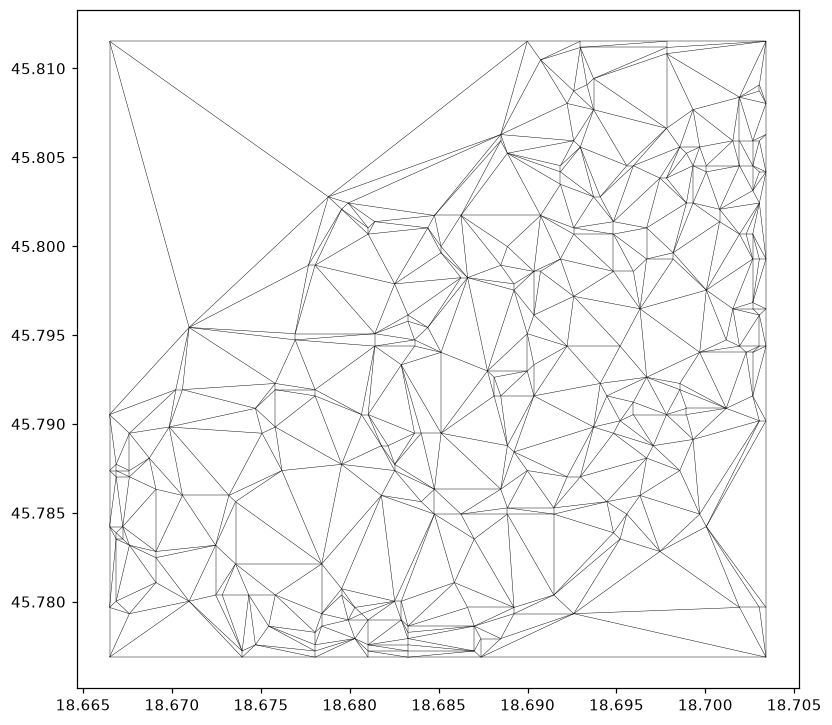

In [8]:
ds.plot_outline(); show()

## 8. Data map

`node_z` is the per-node surface elevation. Note in `summary()` the min is a huge negative number (`-3.4e38`): that is GDAL's **nodata fill** on nodes outside the valid hull, which we mask before plotting (next section).

**Nodata guard.** ESRI TIN elevations carry a GDAL fill value (`-3.4e38`) on nodes outside the triangulated hull. Plotting it raw would blow out the colour scale, so we mask it to `nan` and attach the cleaned field with `with_variable` before plotting.

In [9]:
z = np.asarray(ds.get_data("node_z").data)
z = np.where(z < -1e30, np.nan, z)
ds = ds.with_variable("elevation", z, location="node")
float(np.nanmin(z)), float(np.nanmax(z))

(85.69999694824219, 240.44415283203125)

The real elevations span ~86–240 m. With the fill masked out the colour scale is meaningful:

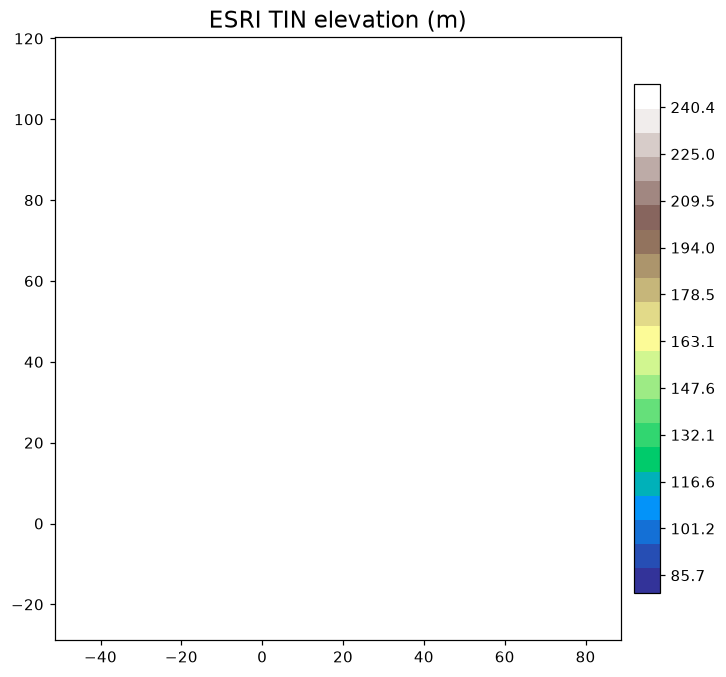

In [10]:
ds.plot("elevation", cmap="terrain", colorbar=True,
        title="ESRI TIN elevation (m)"); show()

## 9. GIS operations for free

The mesh is a pyramids object, so the vector/GIS layer applies unchanged. Convert to a GeoDataFrame — one polygon per element. `to_geodataframe()` returns just the geometry column, so we attach each element's **area** and let geopandas colour by it; smaller cells reveal where the mesh is refined.

In [11]:
gdf = ds.to_geodataframe()
gdf["face_area"] = np.asarray(ds.mesh.face_areas)
gdf.head()

,geometry,face_area
0,"POLYGON ((18.70155 45.79648, 18.70005 45.79753...",1.501325e-06
1,"POLYGON ((18.68513 45.78948, 18.68775 45.79298...",5.940025e-06
2,"POLYGON ((18.69259 45.80103, 18.69185 45.80348...",2.023525e-06
3,"POLYGON ((18.68476 45.78493, 18.68625 45.78493...",1.044400e-06
4,"POLYGON ((18.69409 45.80278, 18.69595 45.80453...",3.263750e-07


Colour the elements by area with geopandas — the per-element column rides along with the geometry:

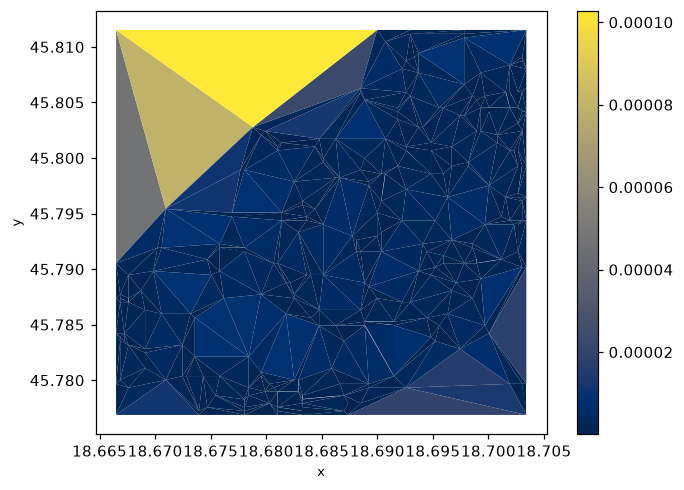

In [12]:
gdf.plot(column="face_area", cmap="cividis", figsize=(7, 5),
         legend=True); show()

The **bounding polygon** is the dissolved outer hull — the mesh's true footprint — drawn here in red over the wireframe.

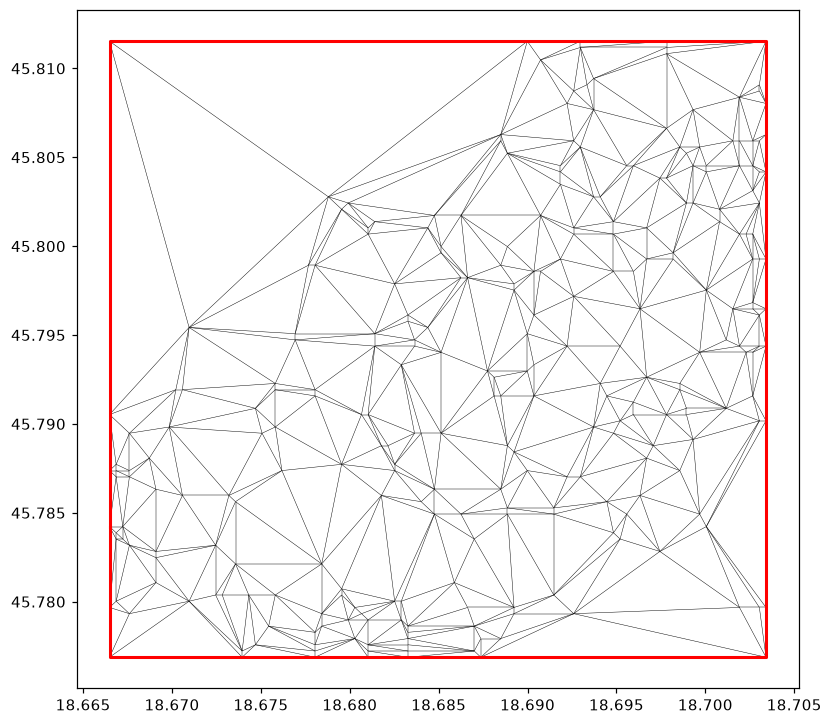

In [13]:
poly = ds.bounding_polygon()
ax = ds.plot_outline().ax
xs, ys = poly.exterior.xy
ax.plot(xs, ys, color="red", lw=2); show()

**Connectivity.** `sparse_adjacency()` is the node-node adjacency (SciPy sparse); `connected_components()` labels each node's component. One component = one unbroken mesh.

In [14]:
adj = ds.sparse_adjacency()
comp = ds.connected_components()
{"adjacency_shape": adj.shape, "nnz": int(adj.nnz),
 "n_components": int(np.unique(comp).size)}

{'adjacency_shape': (528, 528), 'nnz': 1560, 'n_components': 1}

`exterior_edges()` returns the boundary edges (the mesh rim); `circumcenters()` the triangle circumcentres (the dual-mesh vertices used in finite-volume schemes).

In [15]:
ext = ds.exterior_edges()
cc = ds.circumcenters()
{"exterior_edges": int(np.asarray(ext).shape[0]),
 "circumcenters_shape": np.asarray(cc).shape}

{'exterior_edges': 24, 'circumcenters_shape': (528, 2)}

**Spatial subset.** `subset_by_bounds` keeps only faces inside a box, renumbering the connectivity. We take the mesh's own bounds and crop to its lower-left quadrant.

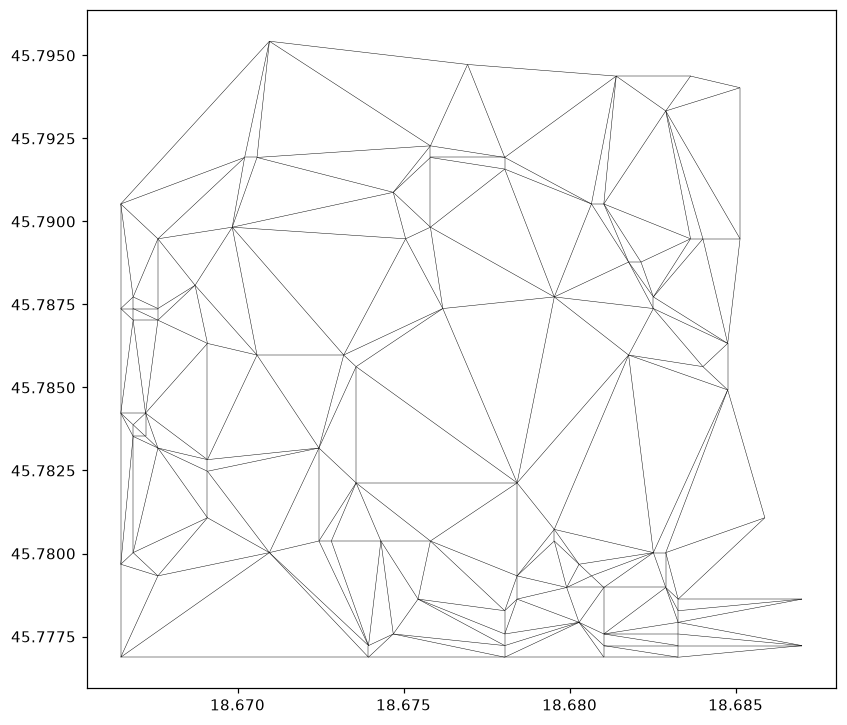

In [16]:
x0, y0, x1, y1 = ds.bounds
sub = ds.subset_by_bounds(x0, y0, (x0 + x1) / 2, (y0 + y1) / 2)
sub.plot_outline(); show()

Only the faces inside the quadrant survive, with their connectivity renumbered:

In [17]:
{"faces_kept": sub.n_face, "of_total": ds.n_face}

{'faces_kept': 170, 'of_total': 528}

**Export.** `to_file` writes the mesh through any writer driver — here an SMS `2dm` grid in a temp folder.

In [18]:
import tempfile
out = Path(tempfile.gettempdir()) / "tin.2dm"
ds.to_file(out, driver="2dm")
{"written": out.name, "exists": out.exists()}

{'written': 'tin.2dm', 'exists': True}

And `to_xarray()` hands the mesh and its variables to the xarray ecosystem:

In [19]:
xds = ds.to_xarray()
type(xds).__name__, list(xds.data_vars)

('Dataset',
 ['mesh2d',
  'mesh2d_node_x',
  'mesh2d_node_y',
  'mesh2d_face_nodes',
  'crs',
  'node_z',
  'elevation'])

## 10. What needs more than a mesh

- **`to_crs(epsg)`** needs a source CRS. this TIN declares no EPSG code, so `ds.epsg is None`, so `to_crs` is skipped.
- **`rasterize_like` / `regrid`** need a *reference grid* to sample onto; with only the mesh in hand there is no target, so they are out of scope for this read-only tour.

## Takeaway

`UgridDataset.read_file(path, driver="esri_tin")` turns the native esri_tin grid into a first-class pyramids mesh. Exploration, plotting, GeoDataFrame conversion, bounding polygons, connectivity analysis, spatial subsetting and export are all inherited from pyramids — `pyramids-mesh` only added the reader.